# BLIP MSR-VTT Retrieval: Zero-Shot vs Fine-Tuned

This notebook runs the MSR-VTT experiment and compares zero-shot BLIP with fine-tuned BLIP using all available test captions.


In [1]:
# Install dependencies if this is a fresh Colab runtime
%pip -q install decord transformers sentencepiece nltk matplotlib


In [2]:
import os

for root, dirs, files in os.walk(
    '/content/drive/Shared drives/DATA 298A/DATA/MSRVTT'
):
    print(root, files[:5])
    if root.count(os.sep) > 8:
        dirs[:] = []

In [3]:
import os
import json
import random
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from transformers import BlipProcessor, BlipForImageTextRetrieval
from decord import VideoReader, cpu

try:
    from google.colab import drive
    drive.mount('/content/drive', force_remount=True)
except ImportError:
    print('Not running in Colab; using local paths.')

Mounted at /content/drive


In [4]:
# Stable, reasonable-runtime full-data configuration
SEED = 298
DATA_ROOT = '/content/drive/Shareddrives/DATA 298A/DATA/MSRVTT'
OUTPUT_DIR = '/content/drive/MyDrive/blip_msrvtt_9k_reasonable_outputs'
MODEL_NAME = 'Salesforce/blip-itm-base-coco'

FRAME_COUNT = 3
FRAME_SAMPLING = 'begin/mid/end'
IMAGE_SIZE = 224
FRAME_OUTPUT_DIR = '/content/blip_frames_224_jpeg'
TOP_K_FRAMES = 2
MAX_TEXT_LEN = 64

SMOKE_TEST = False
RUN_FULL_DATA = True
MAX_VIDEOS = 8
MAX_TRAIN_ITEMS = 600
MAX_VAL_ITEMS = 200

# One caption per training video keeps the full 9K-video experiment practical.
# All available captions remain used for test retrieval evaluation.
EPOCHS = 3
TRAIN_BATCH_SIZE = 64
EVAL_TEXT_BATCH_SIZE = 128
LEARNING_RATE = 2e-5
ENCODER_LEARNING_RATE = 5e-7
UNFREEZE_LAST_N = 1
TEMPERATURE = 0.07
WEIGHT_DECAY = 0.01
EARLY_STOPPING_PATIENCE = 2
NUM_WORKERS = 2

RUN_RETRIEVAL_EVAL = True
RUN_RUNTIME_EVAL = False
RUN_CAPTION_EVAL = False

os.makedirs(OUTPUT_DIR, exist_ok=True)

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

seed_everything()
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)
print('SMOKE_TEST:', SMOKE_TEST)
print('RUN_FULL_DATA:', RUN_FULL_DATA)
print('RUN_RETRIEVAL_EVAL:', RUN_RETRIEVAL_EVAL)
print('Output:', OUTPUT_DIR)


Device: cuda
SMOKE_TEST: False
RUN_FULL_DATA: True
RUN_RETRIEVAL_EVAL: True
Output: /content/drive/MyDrive/blip_msrvtt_9k_reasonable_outputs


## 1. Load MSR-VTT and extract three standardized frames

This section loads the provided MSR-VTT files. The 7K file is used for training, the videos in the 9K file that are not in the 7K file are used for validation, and the official 1K test file is used for testing. Test captions are expanded from `raw_data/MSRVTT_data.json` so every available caption is evaluated as a separate query.


In [5]:
def load_json_file(path):
    with open(path, 'r', encoding='utf-8') as f:
        return json.load(f)

def clean_caption(text):
    return ' '.join(str(text).strip().split())

def make_video_index(video_root):
    index = {}
    for path in Path(video_root).iterdir():
        if path.is_file():
            index[path.name] = str(path)
            index[path.stem] = str(path)
    return index

VIDEO_ROOT = os.path.join(DATA_ROOT, 'raw_videos')
VIDEO_INDEX = make_video_index(VIDEO_ROOT)

def convert_records(records):
    videos = []
    for item in records:
        video_id = str(item['video_id'])
        video_name = str(item['video'])
        video_path = VIDEO_INDEX.get(video_name) or VIDEO_INDEX.get(Path(video_name).stem)
        if not video_path:
            print('Missing video:', video_name)
            continue

        raw_captions = item.get('caption', [])
        captions = [raw_captions] if isinstance(raw_captions, str) else raw_captions
        captions = [clean_caption(x) for x in captions if clean_caption(x)]

        videos.append({
            'video_id': video_id,
            'video_name': video_name,
            'video_path': video_path,
            'captions': list(dict.fromkeys(captions))
        })
    return videos

def sample_indices(total_frames):
    if total_frames <= 0:
        raise ValueError('Video has no frames')
    return [0, total_frames // 2, total_frames - 1]

def extract_frames_as_jpegs(video, output_root=FRAME_OUTPUT_DIR):
    names = ['begin', 'mid', 'end']
    video_dir = Path(output_root) / str(video['video_id'])
    video_dir.mkdir(parents=True, exist_ok=True)
    expected = [video_dir / f'{name}.jpg' for name in names]
    if all(path.exists() for path in expected):
        return [str(path) for path in expected]

    reader = VideoReader(video['video_path'], ctx=cpu(0))
    frames = reader.get_batch(sample_indices(len(reader))).asnumpy()
    paths = []
    for name, array in zip(names, frames):
        image = Image.fromarray(array).convert('RGB')
        image = image.resize((IMAGE_SIZE, IMAGE_SIZE), Image.Resampling.LANCZOS)
        path = video_dir / f'{name}.jpg'
        image.save(path, format='JPEG', quality=95)
        paths.append(str(path))
    return paths

def read_sampled_frames(video_path, frame_paths=None):
    if frame_paths is not None:
        return [Image.open(path).convert('RGB') for path in frame_paths]
    reader = VideoReader(video_path, ctx=cpu(0))
    return [
        Image.fromarray(x).convert('RGB').resize(
            (IMAGE_SIZE, IMAGE_SIZE), Image.Resampling.LANCZOS
        )
        for x in reader.get_batch(sample_indices(len(reader))).asnumpy()
    ]

train_9k_records = load_json_file(os.path.join(DATA_ROOT, 'msrvtt_train_9k.json'))
test_records = load_json_file(os.path.join(DATA_ROOT, 'msrvtt_test_1k.json'))

# Use all 9,000 non-test videos, with a reproducible video-disjoint 90/10 split.
all_train_ids = sorted({str(item['video_id']) for item in train_9k_records})
split_rng = random.Random(SEED)
split_rng.shuffle(all_train_ids)
num_validation = int(0.10 * len(all_train_ids))
val_ids = set(all_train_ids[:num_validation])
train_ids = set(all_train_ids[num_validation:])
train_records = [item for item in train_9k_records if str(item['video_id']) in train_ids]
val_records = [item for item in train_9k_records if str(item['video_id']) in val_ids]

# Expand the one-caption test records using the full MSR-VTT metadata.
full_caption_path = os.path.join(DATA_ROOT, 'raw_data', 'MSRVTT_data.json')
full_metadata = load_json_file(full_caption_path)
caption_map = {}
for sentence in full_metadata['sentences']:
    video_id = str(sentence['video_id'])
    caption = clean_caption(sentence['caption'])
    caption_map.setdefault(video_id, [])
    if caption and caption not in caption_map[video_id]:
        caption_map[video_id].append(caption)

test_records_full = []
for item in test_records:
    item_copy = dict(item)
    video_id = str(item_copy['video_id'])
    item_copy['caption'] = caption_map.get(video_id, [item_copy['caption']])
    test_records_full.append(item_copy)

train_videos = convert_records(train_records)
val_videos = convert_records(val_records)
test_videos = convert_records(test_records_full)

print({
    'train_videos': len(train_videos),
    'validation_videos': len(val_videos),
    'test_videos': len(test_videos),
    'test_caption_queries': sum(len(x['captions']) for x in test_videos)
})

assert set(x['video_id'] for x in train_videos).isdisjoint(x['video_id'] for x in val_videos)
assert set(x['video_id'] for x in train_videos).isdisjoint(x['video_id'] for x in test_videos)
assert set(x['video_id'] for x in val_videos).isdisjoint(x['video_id'] for x in test_videos)

limit = None if RUN_FULL_DATA else MAX_VIDEOS
if limit is not None:
    train_videos = train_videos[:limit]
    val_videos = val_videos[:limit]
    test_videos = test_videos[:limit]

for video in tqdm(train_videos + val_videos + test_videos, desc='Caching frames'):
    video['frame_paths'] = extract_frames_as_jpegs(video)


{'train_videos': 8100, 'validation_videos': 900, 'test_videos': 1000, 'test_caption_queries': 18620}


Caching frames:   0%|          | 0/10000 [00:00<?, ?it/s]

## 2. Dataset with video identifiers

The `video_id` is retained so the loss can recognize multiple valid image-caption pairs from the same video.

In [6]:
processor = BlipProcessor.from_pretrained(MODEL_NAME)

class FrameCaptionDataset(Dataset):
    # One deterministic caption per video keeps the full 9K-video run practical.
    # The test evaluator below still uses every available caption as a query.
    def __init__(self, videos, processor, max_items=None):
        self.processor = processor
        self.items = []
        for video in videos:
            if not video['captions']:
                continue
            caption = video['captions'][0]
            for frame_index in range(FRAME_COUNT):
                self.items.append((video, caption, frame_index))
        if max_items is not None:
            self.items = self.items[:max_items]

    def __len__(self):
        return len(self.items)

    def __getitem__(self, index):
        video, caption, frame_index = self.items[index]
        frame = Image.open(video['frame_paths'][frame_index]).convert('RGB')
        encoded = self.processor(images=frame, text=caption,
                                 padding='max_length', truncation=True,
                                 max_length=MAX_TEXT_LEN, return_tensors='pt')
        output = {key: value.squeeze(0) for key, value in encoded.items()}
        output['video_id'] = video['video_id']
        return output

train_dataset = FrameCaptionDataset(
    train_videos, processor,
    max_items=None if RUN_FULL_DATA else MAX_TRAIN_ITEMS)
val_dataset = FrameCaptionDataset(
    val_videos, processor,
    max_items=None if RUN_FULL_DATA else MAX_VAL_ITEMS)

train_loader = DataLoader(
    train_dataset, batch_size=TRAIN_BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available(),
    persistent_workers=(NUM_WORKERS > 0))
val_loader = DataLoader(
    val_dataset, batch_size=TRAIN_BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available(),
    persistent_workers=(NUM_WORKERS > 0))

print('Training examples:', len(train_dataset))
print('Validation examples:', len(val_dataset))


preprocessor_config.json:   0%|          | 0.00/445 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.56k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/456 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

Training examples: 24300
Validation examples: 2700


## 3. Video-aware BLIP fine-tuning

The multi-positive loss averages the log probability over every matching video in the batch. This prevents captions and frames from the same video being incorrectly penalized as negatives.

In [7]:
model = BlipForImageTextRetrieval.from_pretrained(MODEL_NAME).to(DEVICE)

# Freeze everything first; only the projection heads and final encoder blocks
# selected below may receive gradients.
for parameter in model.parameters():
    parameter.requires_grad = False

vision_blocks = list(getattr(model.vision_model.encoder, 'layers', []))
text_blocks = list(getattr(model.text_encoder.encoder, 'layer', []))
if UNFREEZE_LAST_N > 0:
    for block in vision_blocks[-UNFREEZE_LAST_N:]:
        for parameter in block.parameters():
            parameter.requires_grad = True
    for block in text_blocks[-UNFREEZE_LAST_N:]:
        for parameter in block.parameters():
            parameter.requires_grad = True

projection_parameters = list(model.vision_proj.parameters()) + list(model.text_proj.parameters())
for parameter in projection_parameters:
    parameter.requires_grad = True
projection_ids = {id(parameter) for parameter in projection_parameters}
encoder_parameters = [
    parameter for parameter in model.parameters()
    if parameter.requires_grad and id(parameter) not in projection_ids
]
trainable_parameters = projection_parameters + encoder_parameters

trainable_count = sum(p.numel() for p in trainable_parameters)
print('Projection parameters:', sum(p.numel() for p in projection_parameters))
print('Unfrozen encoder parameters:', sum(p.numel() for p in encoder_parameters))
print('Total trainable parameters:', trainable_count)
assert trainable_count < 50_000_000, 'Unexpectedly many trainable parameters; freezing failed.'

optimizer = torch.optim.AdamW(
    [
        {'params': projection_parameters, 'lr': LEARNING_RATE},
        {'params': encoder_parameters, 'lr': ENCODER_LEARNING_RATE}
    ],
    weight_decay=WEIGHT_DECAY
)

def move_batch(batch):
    return {
        key: value.to(DEVICE, non_blocking=True)
        for key, value in batch.items()
        if key in {'pixel_values', 'input_ids', 'attention_mask'}
    }

def multi_positive_cross_entropy(logits, positive_mask):
    log_probs = F.log_softmax(logits, dim=1)
    positive_mask = positive_mask.float()
    return -((log_probs * positive_mask).sum(dim=1) /
             positive_mask.sum(dim=1).clamp_min(1.0)).mean()

def contrastive_loss(batch, video_ids):
    image_out = model.vision_model(pixel_values=batch['pixel_values'], return_dict=True)
    image_features = F.normalize(
        model.vision_proj(image_out.last_hidden_state[:, 0, :]), dim=-1)
    text_out = model.text_encoder(
        input_ids=batch['input_ids'], attention_mask=batch['attention_mask'],
        return_dict=True)
    text_features = F.normalize(
        model.text_proj(text_out.last_hidden_state[:, 0, :]), dim=-1)
    logits = (image_features @ text_features.T) / TEMPERATURE
    positive = torch.tensor(
        [[left == right for right in video_ids] for left in video_ids],
        device=DEVICE, dtype=torch.bool)
    return 0.5 * (
        multi_positive_cross_entropy(logits, positive) +
        multi_positive_cross_entropy(logits.T, positive.T))

def run_epoch(loader, training):
    model.train(training)
    total, count = 0.0, 0
    for batch in tqdm(loader, desc='train' if training else 'validation', leave=False):
        video_ids = list(batch['video_id'])
        numeric_batch = move_batch(batch)
        with torch.set_grad_enabled(training):
            loss = contrastive_loss(numeric_batch, video_ids)
            if training:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                torch.nn.utils.clip_grad_norm_(trainable_parameters, 1.0)
                optimizer.step()
        size = numeric_batch['input_ids'].size(0)
        total += loss.item() * size
        count += size
    return total / max(count, 1)

history = []
best_val = float('inf')
best_epoch = 0
for epoch in range(1, EPOCHS + 1):
    train_loss = run_epoch(train_loader, True)
    val_loss = run_epoch(val_loader, False)
    row = {'epoch': epoch, 'train_loss': train_loss, 'val_loss': val_loss}
    history.append(row)
    print(row)
    with open(os.path.join(OUTPUT_DIR, 'training_history.json'), 'w') as f:
        json.dump(history, f, indent=2)
    if val_loss < best_val:
        best_val = val_loss
        best_epoch = epoch
        model.save_pretrained(os.path.join(OUTPUT_DIR, 'best_checkpoint'))
        processor.save_pretrained(os.path.join(OUTPUT_DIR, 'best_checkpoint'))
    if epoch - best_epoch >= EARLY_STOPPING_PATIENCE:
        print('Early stopping: validation loss did not improve.')
        break
print('Best epoch:', best_epoch)


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  895MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/472 [00:00<?, ?it/s]

Projection parameters: 393728
Unfrozen encoder parameters: 16539648
Total trainable parameters: 16933376


train:   0%|          | 0/380 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  895MB            

... (9 outputs left out)

validation:   0%|          | 0/43 [00:00<?, ?it/s]

{'epoch': 3, 'train_loss': 1.6259002060850951, 'val_loss': 2.165992942739416}


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Best epoch: 3


## 4. BLIP retrieval evaluation and comparison

Every MSR-VTT caption is used as a text query. A video is represented by its frame embeddings, and its score is the mean of the two strongest frame similarities. The reported metrics compare the original zero-shot BLIP model with the fine-tuned checkpoint.

Loading weights:   0%|          | 0/472 [00:00<?, ?it/s]

Encoding videos:   0%|          | 0/1000 [00:00<?, ?it/s]

Encoding queries:   0%|          | 0/146 [00:00<?, ?it/s]

Ranking:   0%|          | 0/18620 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/472 [00:00<?, ?it/s]

Encoding videos:   0%|          | 0/1000 [00:00<?, ?it/s]

Encoding queries:   0%|          | 0/146 [00:00<?, ?it/s]

Ranking:   0%|          | 0/18620 [00:00<?, ?it/s]

,Metric,Zero-shot BLIP,Fine-tuned BLIP,Change
0,R@1,0.314125,0.338238,0.024114
1,R@5,0.546563,0.590709,0.044146
2,R@10,0.644415,0.690977,0.046563
3,MRR,0.425246,0.456921,0.031675
4,MeanRank,39.012675,27.079699,-11.932975
5,MedianRank,4.000000,3.000000,-1.000000


,K,TP,FP,FN,TN,Precision,Recall,F1
0,1,6298,12322,12322,18589058,0.338238,0.338238,0.338238
1,5,10999,82101,7621,18519279,0.118142,0.590709,0.196903
2,10,12866,173334,5754,18428046,0.069098,0.690977,0.125632


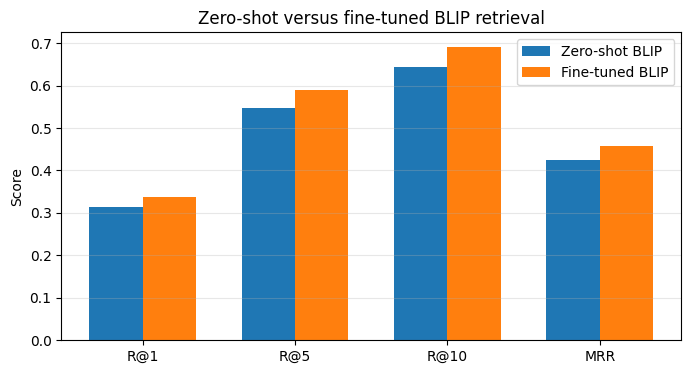

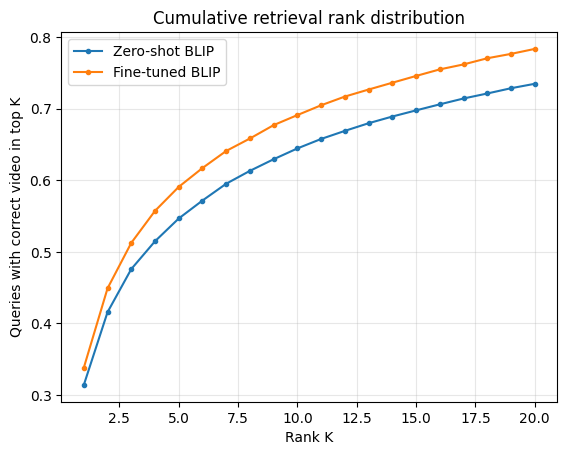

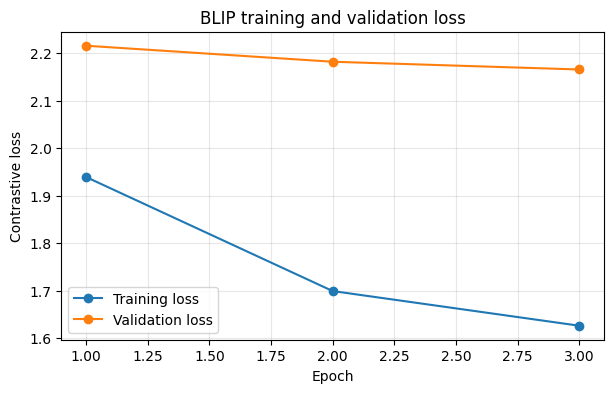

In [8]:
import time
import math
from collections import Counter
import matplotlib.pyplot as plt
from transformers import BlipForConditionalGeneration
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction

@torch.inference_mode()
def encode_image_frames(eval_model, eval_processor, images):
    inputs = eval_processor(images=images, return_tensors='pt')
    outputs = eval_model.vision_model(pixel_values=inputs['pixel_values'].to(DEVICE), return_dict=True)
    features = eval_model.vision_proj(outputs.last_hidden_state[:, 0, :])
    return F.normalize(features, dim=-1).cpu()

@torch.inference_mode()
def encode_text_queries(eval_model, eval_processor, texts):
    inputs = eval_processor(text=texts, padding=True, truncation=True,
                            max_length=MAX_TEXT_LEN, return_tensors='pt')
    outputs = eval_model.text_encoder(input_ids=inputs['input_ids'].to(DEVICE),
                                      attention_mask=inputs['attention_mask'].to(DEVICE),
                                      return_dict=True)
    features = eval_model.text_proj(outputs.last_hidden_state[:, 0, :])
    return F.normalize(features, dim=-1).cpu()

@torch.inference_mode()
def evaluate_retrieval(eval_model, eval_processor, videos):
    eval_model.eval()
    video_ids, video_embeddings = [], []
    for video in tqdm(videos, desc='Encoding videos'):
        frame_embeddings = encode_image_frames(
            eval_model, eval_processor,
            read_sampled_frames(video['video_path'], video['frame_paths']))
        video_ids.append(video['video_id'])
        video_embeddings.append(frame_embeddings)

    queries, targets = [], []
    for video in videos:
        for caption in video['captions']:
            queries.append(caption)
            targets.append(video['video_id'])

    query_embeddings = []
    for start in tqdm(range(0, len(queries), EVAL_TEXT_BATCH_SIZE), desc='Encoding queries'):
        query_embeddings.append(encode_text_queries(
            eval_model, eval_processor, queries[start:start + EVAL_TEXT_BATCH_SIZE]))
    query_embeddings = torch.cat(query_embeddings, dim=0)

    ranks = []
    for query_embedding, target in tqdm(zip(query_embeddings, targets), total=len(targets), desc='Ranking'):
        scores = []
        for frame_embeddings in video_embeddings:
            similarities = frame_embeddings @ query_embedding
            k = min(TOP_K_FRAMES, similarities.numel())
            scores.append(torch.topk(similarities, k=k).values.mean().item())
        order = np.argsort(-np.asarray(scores))
        rank = int(np.where(np.asarray(video_ids)[order] == target)[0][0]) + 1
        ranks.append(rank)

    ranks = np.asarray(ranks)
    return {'R@1': float(np.mean(ranks <= 1)), 'R@5': float(np.mean(ranks <= 5)),
            'R@10': float(np.mean(ranks <= 10)), 'MRR': float(np.mean(1.0 / ranks)),
            'MeanRank': float(np.mean(ranks)), 'MedianRank': float(np.median(ranks)),
            'num_queries': int(len(ranks)), 'num_videos': int(len(video_ids)),
            'ranks': ranks.tolist()}

def relevance_confusion_metrics(ranks, num_videos, k):
    ranks = np.asarray(ranks)
    hits = ranks <= k
    tp = int(hits.sum()); fn = int((~hits).sum())
    fp = int(np.maximum(np.where(hits, k - 1, k), 0).sum())
    tn = int(np.maximum(num_videos - k - np.where(hits, 0, 1), 0).sum())
    precision = tp / max(tp + fp, 1)
    recall = tp / max(tp + fn, 1)
    f1 = 2 * precision * recall / max(precision + recall, 1e-12)
    return {'K': k, 'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn,
            'Precision': precision, 'Recall': recall, 'F1': f1}

def timed_retrieval_evaluation(model, eval_processor, videos):
    start = time.perf_counter()
    metrics = evaluate_retrieval(model, eval_processor, videos)
    elapsed = time.perf_counter() - start
    metrics['evaluation_time_sec'] = float(elapsed)
    metrics['avg_query_time_sec'] = float(elapsed / max(metrics['num_queries'], 1))
    return metrics

if RUN_RETRIEVAL_EVAL:
    fine_tuned_model = BlipForImageTextRetrieval.from_pretrained(
        os.path.join(OUTPUT_DIR, 'best_checkpoint')).to(DEVICE)
    fine_tuned_processor = BlipProcessor.from_pretrained(
        os.path.join(OUTPUT_DIR, 'best_checkpoint'))
    fine_tuned_metrics = evaluate_retrieval(fine_tuned_model, fine_tuned_processor, test_videos)
    del fine_tuned_model, fine_tuned_processor
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    zero_shot_model = BlipForImageTextRetrieval.from_pretrained(MODEL_NAME).to(DEVICE)
    zero_shot_processor = BlipProcessor.from_pretrained(MODEL_NAME)
    zero_shot_metrics = evaluate_retrieval(zero_shot_model, zero_shot_processor, test_videos)

    metric_names = ['R@1', 'R@5', 'R@10', 'MRR', 'MeanRank', 'MedianRank']
    comparison = pd.DataFrame({
        'Metric': metric_names,
        'Zero-shot BLIP': [zero_shot_metrics[name] for name in metric_names],
        'Fine-tuned BLIP': [fine_tuned_metrics[name] for name in metric_names]})
    comparison['Change'] = comparison['Fine-tuned BLIP'] - comparison['Zero-shot BLIP']
    display(comparison)
    comparison.to_csv(os.path.join(OUTPUT_DIR, 'zero_shot_vs_fine_tuned_comparison.csv'), index=False)

    relevance_df = pd.DataFrame([relevance_confusion_metrics(
        fine_tuned_metrics['ranks'], fine_tuned_metrics['num_videos'], k) for k in [1, 5, 10]])
    display(relevance_df)
    relevance_df.to_csv(os.path.join(OUTPUT_DIR, 'binary_relevance_metrics.csv'), index=False)

    with open(os.path.join(OUTPUT_DIR, 'zero_shot_vs_fine_tuned_comparison.json'), 'w') as f:
        json.dump({'zero_shot': zero_shot_metrics, 'fine_tuned': fine_tuned_metrics,
                   'configuration': {'dataset': 'MSR-VTT', 'model': MODEL_NAME,
                                     'full_data': RUN_FULL_DATA, 'epochs': EPOCHS,
                                     'batch_size': TRAIN_BATCH_SIZE, 'frame_count': FRAME_COUNT,
                                     'top_k_frames': TOP_K_FRAMES, 'learning_rate': LEARNING_RATE,
                                     'encoder_learning_rate': ENCODER_LEARNING_RATE,
                                     'unfreeze_last_n': UNFREEZE_LAST_N, 'temperature': TEMPERATURE,
                                     'multi_positive_loss': True}}, f, indent=2)

    if RUN_RUNTIME_EVAL:
        runtime_model = BlipForImageTextRetrieval.from_pretrained(
            os.path.join(OUTPUT_DIR, 'best_checkpoint')).to(DEVICE)
        runtime_processor = BlipProcessor.from_pretrained(
            os.path.join(OUTPUT_DIR, 'best_checkpoint'))
        runtime_metrics = timed_retrieval_evaluation(runtime_model, runtime_processor, test_videos)
        with open(os.path.join(OUTPUT_DIR, 'blip_runtime_metrics.json'), 'w') as f:
            json.dump(runtime_metrics, f, indent=2)
        print({k: runtime_metrics[k] for k in ['evaluation_time_sec', 'avg_query_time_sec']})
        del runtime_model, runtime_processor
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    plot_rows = []
    for name, metrics in [('Zero-shot BLIP', zero_shot_metrics), ('Fine-tuned BLIP', fine_tuned_metrics)]:
        for metric in ['R@1', 'R@5', 'R@10', 'MRR']:
            plot_rows.append({'Model': name, 'Metric': metric, 'Score': metrics[metric]})
    plot_df = pd.DataFrame(plot_rows)
    plt.figure(figsize=(8, 4))
    for i, name in enumerate(plot_df['Model'].unique()):
        vals = plot_df[plot_df['Model'] == name]['Score'].values
        plt.bar(np.arange(4) + (i - .5) * .35, vals, width=.35, label=name)
    plt.xticks(np.arange(4), ['R@1', 'R@5', 'R@10', 'MRR'])
    plt.ylabel('Score'); plt.title('Zero-shot versus fine-tuned BLIP retrieval')
    plt.legend(); plt.grid(axis='y', alpha=.3); plt.show()

    for name, metrics in [('Zero-shot BLIP', zero_shot_metrics), ('Fine-tuned BLIP', fine_tuned_metrics)]:
        ranks = np.asarray(metrics['ranks'])
        xs = np.arange(1, 21)
        plt.plot(xs, [np.mean(ranks <= x) for x in xs], marker='.', label=name)
    plt.xlabel('Rank K'); plt.ylabel('Queries with correct video in top K')
    plt.title('Cumulative retrieval rank distribution'); plt.legend(); plt.grid(alpha=.3); plt.show()

# Optional caption metrics. Disabled by default because this is separate from retrieval.
def ngrams(tokens, n):
    return [tuple(tokens[i:i+n]) for i in range(len(tokens)-n+1)]

def cider_score(candidate, references):
    cand_tokens = candidate.lower().split(); ref_tokens = [r.lower().split() for r in references]
    document_frequency = {}
    for n in range(1, 5):
        for ref in ref_tokens:
            for gram in set(ngrams(ref, n)):
                document_frequency[(n, gram)] = document_frequency.get((n, gram), 0) + 1
    num_docs = max(len(ref_tokens), 1)
    def vector(tokens, n):
        counts = Counter(ngrams(tokens, n)); vec = {}
        for gram, count in counts.items():
            df = document_frequency.get((n, gram), 0)
            vec[gram] = (count / max(sum(counts.values()), 1)) * math.log((num_docs + 1) / (df + 1))
        return vec
    scores = []
    for n in range(1, 5):
        cv = vector(cand_tokens, n); cn = math.sqrt(sum(x*x for x in cv.values())); ref_scores = []
        for ref in ref_tokens:
            rv = vector(ref, n); rn = math.sqrt(sum(x*x for x in rv.values()))
            dot = sum(cv.get(g, 0.0) * rv.get(g, 0.0) for g in set(cv) | set(rv))
            ref_scores.append(dot / max(cn * rn, 1e-12))
        scores.append(float(np.mean(ref_scores)) if ref_scores else 0.0)
    return 10.0 * float(np.mean(scores))

@torch.inference_mode()
def generate_video_captions(model, caption_processor, videos):
    predictions, references = [], []
    smooth = SmoothingFunction().method1
    for video in tqdm(videos, desc='Generating BLIP captions'):
        middle_frame = read_sampled_frames(video['video_path'], video['frame_paths'])[1]
        inputs = caption_processor(images=middle_frame, return_tensors='pt').to(DEVICE)
        output_ids = model.generate(**inputs, max_new_tokens=30, num_beams=3, early_stopping=True)
        predictions.append(caption_processor.decode(output_ids[0], skip_special_tokens=True).strip())
        references.append(video['captions'])
    bleu_values, cider_values = [], []
    for prediction, refs in zip(predictions, references):
        ref_tokens = [r.lower().split() for r in refs]
        bleu_values.append(sentence_bleu(ref_tokens, prediction.lower().split(), smoothing_function=smooth))
        cider_values.append(cider_score(prediction, refs))
    return {'BLEU': float(np.mean(bleu_values)), 'CIDEr': float(np.mean(cider_values)),
            'num_videos': len(videos), 'predictions': predictions}

if RUN_CAPTION_EVAL:
    caption_model_name = 'Salesforce/blip-image-captioning-base'
    caption_processor = BlipProcessor.from_pretrained(caption_model_name)
    caption_model = BlipForConditionalGeneration.from_pretrained(caption_model_name).to(DEVICE)
    caption_metrics = generate_video_captions(caption_model, caption_processor, test_videos)
    with open(os.path.join(OUTPUT_DIR, 'blip_caption_metrics.json'), 'w') as f:
        json.dump(caption_metrics, f, indent=2)
    print({k: caption_metrics[k] for k in ['BLEU', 'CIDEr', 'num_videos']})
    del caption_model, caption_processor
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

history_path = os.path.join(OUTPUT_DIR, 'training_history.json')
if os.path.exists(history_path):
    hist = pd.DataFrame(json.load(open(history_path)))
    plt.figure(figsize=(7, 4))
    plt.plot(hist['epoch'], hist['train_loss'], marker='o', label='Training loss')
    plt.plot(hist['epoch'], hist['val_loss'], marker='o', label='Validation loss')
    plt.xlabel('Epoch'); plt.ylabel('Contrastive loss'); plt.title('BLIP training and validation loss')
    plt.legend(); plt.grid(alpha=.3); plt.show()
